# New muon template (step2)
The new muon template (`override/muon/muontemplate_combined_hese_sigma.yaml`) uses the same combined conv/prompt KDE
templates, but its `template_fluctuation` is a 1 sigma error instead of `up - low` (= 2 sigma): same total rate of 12.6 events,
sum of sigma^2 8.54 -> 2.18 events^2. All fits below have the detector priors applied (fixed `prior` key).
Compared: the previous HESE results, SAY with fixed priors (`..._fixedprior`), SAY with the new muon template
(`..._fixedprior_newmuon`), the new SAY vs Poisson fit, and the data flavor triangle.

In [3]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import NNMFit

sys.path.insert(0, "/data/user/tvaneede/GlobalFit/reco_processing/NNMFit/notebooks/unblind/step2_hese_flavor_reunblind")
from analysis_utils import (scan_errors, combine_2d_scans, load_hese75_2d, PREVIOUS_RESULTS,
                            load_triangle_scan, flavor_fractions, latex_comparison_table, PARAMETERS)

plotting_path = "/data/user/tvaneede/GlobalFit/reco_processing/NNMFit/notebooks/unblind/step2_hese_flavor_reunblind/studies/plots_compare_newmuon"
os.makedirs(plotting_path, exist_ok=True)

In [4]:
import matplotlib.font_manager as font_manager
font_axis_label = {'family': 'serif',
        'color':  'black',
        'weight': 'normal',
        'size': 22,
        }
font_title = {'family': 'serif',
        'color':  'black',
        'weight': 'bold',
        'size': 20,
        }
font_legend = font_manager.FontProperties(family='serif',
                                   weight='normal',
                                   style='normal', size=13)

plt.rcParams["figure.figsize"] = (6,6)
plt.rcParams.update({'font.family':'serif'})

## 1D scans

In [5]:
data_fits = "/data/user/tvaneede/GlobalFit/reco_processing/NNMFit/dag_scans/flavor_globalfit/hese/unblind/step2_hese_flavor_reunblind/data_fits"
scan = "nbestfit50_all_param_2sigma_1D_10steps_PassingHESE"
drop_unsuccessful = True  # as in fit_result.ipynb
parameters = PARAMETERS
scan_dirs = {
    "SAY, fixed priors":        f"{data_fits}/{scan}_fixedprior",
    "SAY, new muon":            f"{data_fits}/{scan}_fixedprior_newmuon",
    "Poisson, new muon":        f"{data_fits}/{scan}_Poisson_fixedprior_newmuon",
}
scan_dict = {name: NNMFit.utilities.ScanHandler(d, dump=False, drop_unsuccessful=drop_unsuccessful) for name, d in scan_dirs.items()}
bestfits = {name: s.get_freefit(drop_unsuccessful="True") for name, s in scan_dict.items()}
errors = {name: scan_errors(scan_dict[name], bestfits[name], parameters, drop_unsuccessful) for name in scan_dict}

for name, bf in bestfits.items():
    print(f"{name}: freefit llh = {bf['llh']:.4f}")

SAY, fixed priors: freefit llh = 180.9516
SAY, new muon: freefit llh = 180.1341
Poisson, new muon: freefit llh = 93.9667


In [6]:
def show(columns, parameters):
    df = pd.DataFrame({(name, col): {p: (v[i] if v is not None and v[i] is not None else np.nan) for p, v in res.items()}
                       for name, res in columns.items() for i, col in enumerate(["bestfit", "-1sig", "+1sig"])})
    with pd.option_context("display.float_format", "{:.3f}".format, "display.width", 250, "display.max_columns", 30):
        display(df.reindex(parameters))

## SAY: previous HESE results, fixed priors, fixed priors + new muon template

In [7]:
say_columns = {
    "HESE-7.5": PREVIOUS_RESULTS["HESE-7.5"],
    "HESE-7.5 flavor": PREVIOUS_RESULTS["HESE-7.5 flavor"],
    "HESE-12 flavor": PREVIOUS_RESULTS["HESE-12 flavor"],
    "SAY, fixed priors": errors["SAY, fixed priors"],
    "SAY, new muon":     errors["SAY, new muon"],
}
show(say_columns, parameters)
print(latex_comparison_table(say_columns,
                             caption=r"Step2 best fit values with $1\sigma$ asymmetric uncertainties (SAY): previous HESE results, "
                                     r"this analysis with fixed detector priors, and with the new muon template.",
                             label="tab:step2_newmuon"))

HESE-7.5             HESE-7.5 flavor             HESE-12 flavor             SAY, fixed priors             SAY, new muon            
                       bestfit -1sig +1sig         bestfit -1sig +1sig        bestfit -1sig +1sig           bestfit -1sig +1sig       bestfit -1sig +1sig
astro_norm               2.123 0.540 0.487           3.001   NaN   NaN          2.530 1.490 1.780             3.221 1.107 1.515         3.135 1.084 1.524
gamma_astro              2.870 0.190 0.210           2.890 0.200 0.210          2.840 0.180 0.190             2.860 0.151 0.164         2.859 0.111 0.148
astro_nue_ratio            NaN   NaN   NaN           0.674   NaN   NaN          0.450 0.400 0.680             0.745 0.182 0.351         0.766 0.146 0.438
astro_nutau_ratio          NaN   NaN   NaN           0.651   NaN   NaN          0.896 0.890 1.340             0.037   NaN 0.285         0.037   NaN 0.315
conv_norm                1.010 0.340 0.340           0.970 0.360 0.360          0.990 0.200 0.190             1.006 0.183 0.190         1.007 0.187 0.190
prompt_norm              0.000 0.000 5.340           0.000 0.000 6.100          0.000 0.000 2.250             1.390   NaN 2.614         1.417   NaN 2.604
combined_muongun_norm    1.190 0.440 0.450           1.160 0.450 0.460          1.160 0.430 0.420             0.487 0.086 0.226         0.619 0.200 0.282
muongun_asymmetry          NaN   NaN   NaN             NaN   NaN   NaN            NaN   NaN   NaN             0.242 0.852   NaN         0.610 1.100   NaN
delta_gamma             -0.053 0.131 0.048             NaN   NaN   NaN         -0.000 1.000 1.000            -0.002 0.049 0.049        -0.002 0.047 0.049
CR_grad                    NaN   NaN   NaN             NaN   NaN   NaN          0.042 1.000 2.000            -0.010 0.952 0.895        -0.014   NaN 0.933
barr_h                     NaN   NaN   NaN             NaN   NaN   NaN          0.000 0.500 0.500             0.001 0.147 0.147         0.001 0.144 0.140
barr_w                     NaN   NaN   NaN             NaN   NaN   NaN          0.000 0.500 0.500            -0.000 0.398 0.397         0.000 0.383 0.398
barr_y                     NaN   NaN   NaN             NaN   NaN   NaN          0.000 0.500 0.500             0.015 0.282 0.285         0.018 0.262 0.283
barr_z                     NaN   NaN   NaN             NaN   NaN   NaN          0.000 0.500 0.500             0.011 0.107 0.110         0.012 0.104 0.109
dom_eff                  0.952 0.066 0.093             NaN   NaN   NaN          1.040 0.040 0.060             0.984   NaN 0.046         0.983 0.060 0.043
ice_scat                   NaN   NaN   NaN             NaN   NaN   NaN          0.980 0.040 0.040             0.992 0.038 0.036         0.991 0.035 0.036
ice_abs                    NaN   NaN   NaN             NaN   NaN   NaN          0.990 0.040 0.040             1.026 0.038 0.036         1.026 0.038 0.036
ice_crystal                NaN   NaN   NaN             NaN   NaN   NaN            NaN   NaN   NaN             0.924 0.071 0.074         0.924 0.050 0.074
ice_holep0                 NaN   NaN   NaN             NaN   NaN   NaN         -0.270 0.380 0.280             0.066   NaN 0.185         0.066   NaN 0.182
ice_holep1                 NaN   NaN   NaN             NaN   NaN   NaN         -0.080 0.050 0.040            -0.063 0.029 0.028        -0.063 0.029 0.030

\begin{table}[h]
  \centering
  \caption{Step2 best fit values with $1\sigma$ asymmetric uncertainties (SAY): previous HESE results, this analysis with fixed detector priors, and with the new muon template.}
  \label{tab:step2_newmuon}
  \begin{tabular}{l r r r r r}
    \hline\hline
    Parameter & HESE-7.5 & HESE-7.5 flavor & HESE-12 flavor & SAY, fixed priors & SAY, new muon \\
    \hline
    \hline
    \multicolumn{6}{l}{\textbf{Signal}} \\
    \hline
    $\Phi_{0,\nu_\mu}$ & $2.123^{+0.487}_{-0.540}$ & $3.001$ & $2.530^{+1.780}_{-1.490}$ & $3.221^{+1.515}_{-1.107}$ & $3.135^{+1.524}_{-1.084}$ \\
    $\gamma_\mathrm{astro}$ & $2.870^{+0.210}_{-0.190}$ & $2.890^{+0.210}_{-0.200}$ & $2.840^{+0.190}_{-0.180}$ & $2.860^{+0.164}_{-0.151}$ & $2.859^{+0.148}_{-0.111}$ \\
    $\Phi_{\nu_e}/\Phi_{\nu_\mu}$ & --- & $0.674$ & $0.450^{+0.680}_{-0.400}$ & $0.745^{+0.351}_{-0.182}$ & $0.766^{+0.438}_{-0.146}$ \\
    $\Phi_{\nu_\tau}/\Phi_{\nu_\mu}$ & --- & $0.651$ & $0.896^{+1.340}_{-0.890}$ & $0

## New muon template: SAY vs Poisson

In [8]:
likelihood_columns = {"SAY": errors["SAY, new muon"], "Poisson": errors["Poisson, new muon"]}
show(likelihood_columns, parameters)
print(latex_comparison_table(likelihood_columns,
                             caption=r"Step2 best fit values with $1\sigma$ asymmetric uncertainties with the new muon template, "
                                     r"for the SAY and the Poisson likelihood.",
                             label="tab:step2_newmuon_SAY_Poisson"))

SAY             Poisson            
                      bestfit -1sig +1sig bestfit -1sig +1sig
astro_norm              3.135 1.084 1.524   3.182 1.064 1.426
gamma_astro             2.859 0.111 0.148   2.854 0.152 0.155
astro_nue_ratio         0.766 0.146 0.438   0.741 0.176 0.394
astro_nutau_ratio       0.037   NaN 0.315   0.067   NaN 0.271
conv_norm               1.007 0.187 0.190   1.007 0.187 0.190
prompt_norm             1.417   NaN 2.604   1.647   NaN 2.617
combined_muongun_norm   0.619 0.200 0.282   0.719 0.231 0.261
muongun_asymmetry       0.610 1.100   NaN   1.000 1.103   NaN
delta_gamma            -0.002 0.047 0.049  -0.002 0.049 0.049
CR_grad                -0.014   NaN 0.933  -0.013 0.953 0.931
barr_h                  0.001 0.144 0.140   0.001 0.147 0.147
barr_w                  0.000 0.383 0.398  -0.000 0.397 0.398
barr_y                  0.018 0.262 0.283   0.018 0.281 0.284
barr_z                  0.012 0.104 0.109   0.013 0.107 0.110
dom_eff                 0.983 0.060 0.043   0.981 0.056 0.053
ice_scat                0.991 0.035 0.036   0.989 0.039 0.039
ice_abs                 1.026 0.038 0.036   1.031 0.038 0.036
ice_crystal             0.924 0.050 0.074   0.913 0.080 0.079
ice_holep0              0.066   NaN 0.182   0.034   NaN 0.211
ice_holep1             -0.063 0.029 0.030  -0.064 0.031 0.031

\begin{table}[h]
  \centering
  \caption{Step2 best fit values with $1\sigma$ asymmetric uncertainties with the new muon template, for the SAY and the Poisson likelihood.}
  \label{tab:step2_newmuon_SAY_Poisson}
  \begin{tabular}{l r r}
    \hline\hline
    Parameter & SAY & Poisson \\
    \hline
    \hline
    \multicolumn{3}{l}{\textbf{Signal}} \\
    \hline
    $\Phi_{0,\nu_\mu}$ & $3.135^{+1.524}_{-1.084}$ & $3.182^{+1.426}_{-1.064}$ \\
    $\gamma_\mathrm{astro}$ & $2.859^{+0.148}_{-0.111}$ & $2.854^{+0.155}_{-0.152}$ \\
    $\Phi_{\nu_e}/\Phi_{\nu_\mu}$ & $0.766^{+0.438}_{-0.146}$ & $0.741^{+0.394}_{-0.176}$ \\
    $\Phi_{\nu_\tau}/\Phi_{\nu_\mu}$ & $0.037^{+0.315}_{---}$ & $0.067^{+0.271}_{---}$ \\
    \hline
    \multicolumn{3}{l}{\textbf{Flux nuisance}} \\
    \hline
    $\Phi_\mathrm{conv}$ & $1.007^{+0.190}_{-0.187}$ & $1.007^{+0.190}_{-0.187}$ \\
    $\Phi_\mathrm{prompt}$ & $1.417^{+2.604}_{---}$ & $1.647^{+2.617}_{---}$ \\
    $\Phi_\mathrm{muon}$ & $0.619^{+0.282}_{-0.20

## Flavor triangle
SAY with fixed priors: `nbestfit50_fixedprior_0`; with the new muon template: `nbestfit50_fixedprior_newmuon_0` (SAY) and
`nbestfit50_Poisson_fixedprior_newmuon_0` (Poisson). All scan points are used (`drop_unsuccessful_points=False`, see `asimov_closure.ipynb`).

In [9]:
sys.path.append("/data/user/tvaneede/GlobalFit/reco_processing/NNMFit/notebooks")
from plot_utils_triangle import *

triangle_path = "/data/user/tvaneede/GlobalFit/reco_processing/NNMFit/dag_scans/flavor_globalfit/hese/unblind/step2_hese_flavor_reunblind/data_fits_flavor_triangle"
tri_scan_dirs = {
    "SAY, fixed priors": f"{triangle_path}/nbestfit50_fixedprior_0",
    "SAY, new muon":     f"{triangle_path}/nbestfit50_fixedprior_newmuon_0",
    "Poisson, new muon": f"{triangle_path}/nbestfit50_Poisson_fixedprior_newmuon_0",
}
N_grid = 40
tri_scans, tri_data, tri_bestfits = {}, {}, {}
for name, scan_dir in tri_scan_dirs.items():
    tri_scans[name], tri_data[name], tri_bestfits[name] = load_triangle_scan(scan_dir, N_grid=N_grid, drop_unsuccessful_points=False)
    print(f"{name}: {tri_data[name]['n_converged']} converged, {len(tri_data[name]['ts'])} used scan points, "
          f"freefit llh = {tri_bestfits[name]['llh']:.4f}")
tri_names = list(tri_scan_dirs)

tri_parameters = ["astro_norm", "gamma_astro", "astro_nue_ratio", "astro_nutau_ratio", "f_e", "f_mu", "f_tau"]
tri_results = {name: {**{p: tri_bestfits[name][p] for p in tri_parameters[:4]}, **flavor_fractions(tri_bestfits[name])}
               for name in tri_names}
with pd.option_context("display.float_format", "{:.3f}".format):
    display(pd.DataFrame(tri_results).loc[tri_parameters])

removed stuff
SAY, fixed priors: 204 converged, 270 used scan points, freefit llh = 180.9516
removed stuff
SAY, new muon: 192 converged, 270 used scan points, freefit llh = 180.1341
removed stuff
Poisson, new muon: 270 converged, 270 used scan points, freefit llh = 93.9667


,"SAY, fixed priors","SAY, new muon","Poisson, new muon"
astro_norm,3.222,3.135,3.182
gamma_astro,2.860,2.859,2.854
astro_nue_ratio,0.745,0.766,0.741
astro_nutau_ratio,0.037,0.037,0.067
f_e,0.418,0.425,0.410
f_mu,0.561,0.555,0.553
f_tau,0.020,0.021,0.037


/data/user/tvaneede/utils/Ternary.py:74: UserWarning: First parameter to grid() is false, but line properties are supplied. The grid will be enabled.
  ax.xaxis.grid(*args, **kwargs)


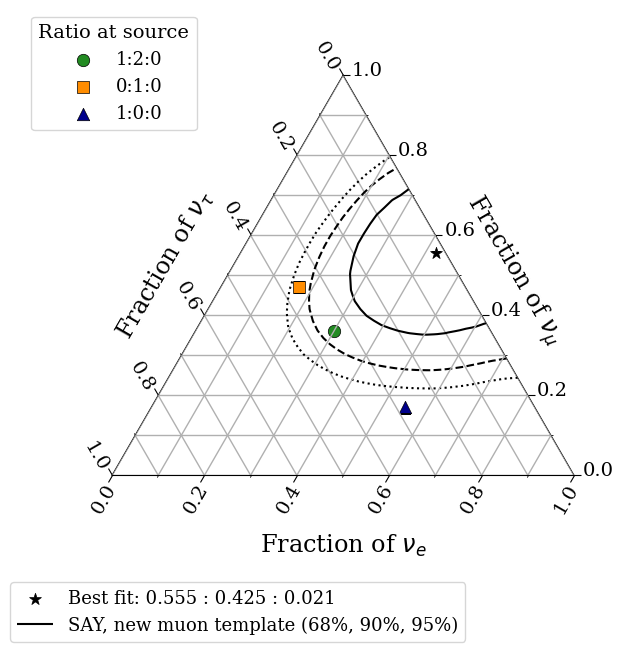

In [10]:
fr = flavor_fractions(tri_bestfits["SAY, new muon"])
C = plot_contour(data=tri_data, name="SAY, new muon", label="SAY, new muon template", levels=["68%", "90%", "95%"], title="",
                 scenarios=True, show_ts_labels=False, bestfit=[fr["f_tau"], fr["f_e"]],
                 savepath=f"{plotting_path}/flavor_triangle_newmuon.png")
plt.show()

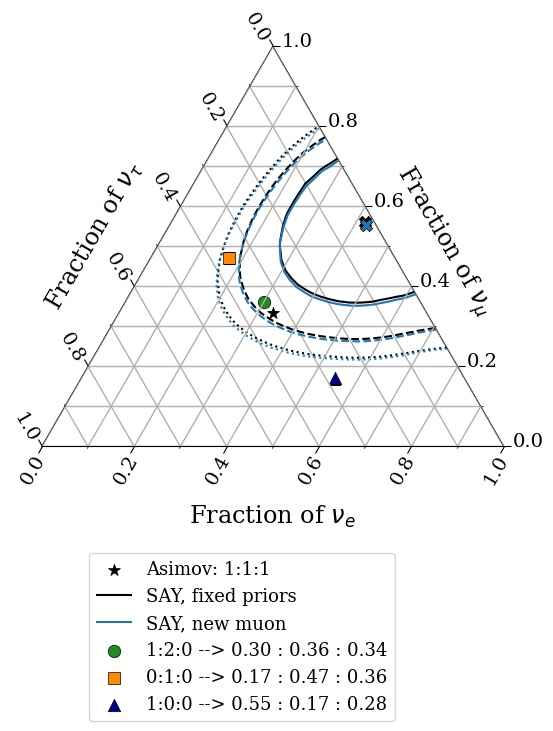

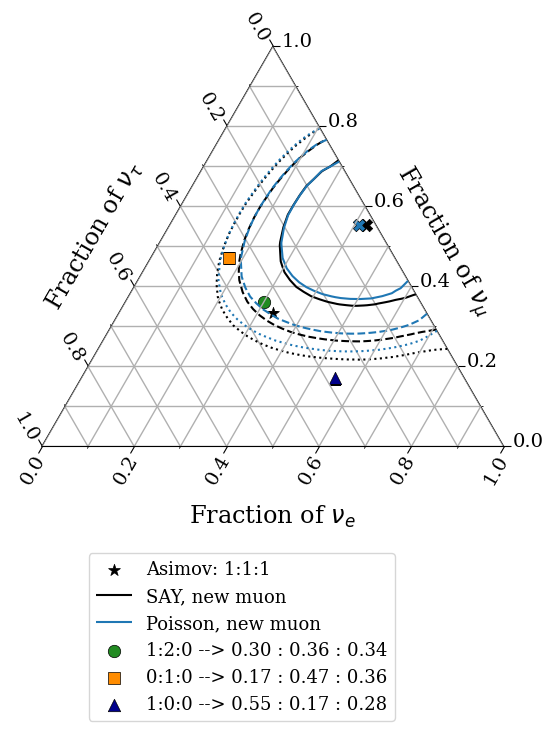

In [11]:
def plot_triangles(names, savepath):
    C = compare_contours(tri_data, names=names, labels=names, levels=["68%", "90%", "95%"], title="", scenarios=True)
    ax = plt.gca()
    for i, name in enumerate(names):
        fr = flavor_fractions(tri_bestfits[name])
        ax.scatter([fr["f_tau"]], [fr["f_e"]], marker="X", facecolor=colours[i], edgecolor="k", lw=0.5, s=80, zorder=10)
    plt.savefig(savepath, bbox_inches="tight")
    plt.show()

plot_triangles(["SAY, fixed priors", "SAY, new muon"], f"{plotting_path}/flavor_triangle_fixedprior_vs_newmuon.png")
plot_triangles(["SAY, new muon", "Poisson, new muon"], f"{plotting_path}/flavor_triangle_newmuon_SAY_vs_Poisson.png")